In [22]:
#0 Function that takes X and Y and returns B_0 and B_1
import numpy as np
from scipy import stats as st
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Test Case
X = np.random.default_rng().integers(low=0,high=1000,size=100)
Y = np.random.default_rng().integers(low=0,high=1000,size=100)

def myReg(X,Y):
    beta1 = st.pearsonr(X, Y)[0] * np.std(Y) / np.std(X)
    beta0 = np.mean(Y) - np.mean(X) * beta1
    return beta0, beta1

#fucntion from lecture 
lecturefunc = (st.linregress (X,Y))

b0, b1 = myReg(X,Y)

#check results
print ("Prewritten Function Values", lecturefunc.intercept, lecturefunc.slope)
print("My Function Values",b0, b1)


Prewritten Function Values 561.1475726702118 -0.13102720219988873
My Function Values 561.1475726702118 -0.1310272021998888


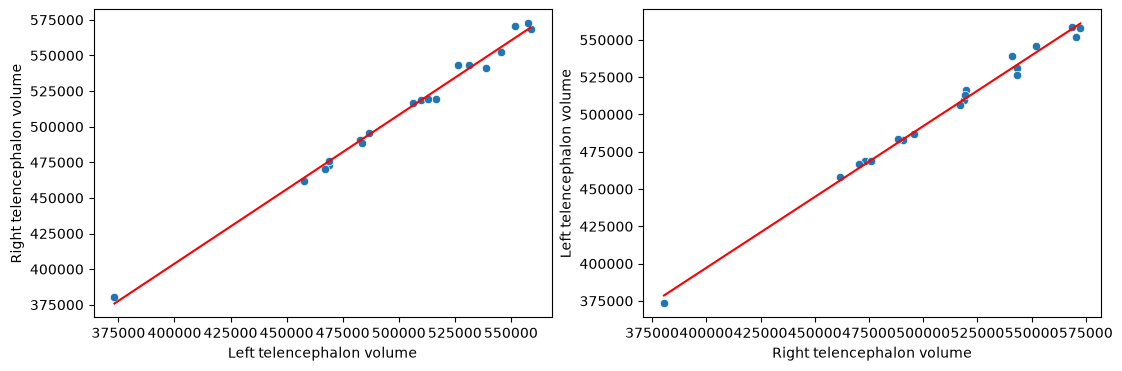

In [47]:
#1 Kirby21 Regression Model
## Read in the data and display a few rows
ds = pd.read_csv("https://raw.githubusercontent.com/smart-stats/ds4bio_book/refs/heads/main/qbook/assets/kirby21.csv")
ds.head(4)
T_L=ds.loc[ds['roi'] == 'Telencephalon_L','volume'].to_numpy()
T_R=ds.loc[ds['roi'] == 'Telencephalon_R','volume'].to_numpy()

#use regression model from problem 1
b0_LR, b1_LR = myReg(T_L, T_R)   # left to right
b0_RL, b1_RL = myReg(T_R, T_L)   # right to left

fig,axes = plt.subplots(1,2,figsize=(13, 4))

#Left to Right
sns.scatterplot(x=T_L, y=T_R, ax=axes[0])
xs = np.array([T_L.min(), T_L.max()])
axes[0].plot(xs, b0_LR + b1_LR * xs, color='red')
axes[0].set_xlabel('Left telencephalon volume')
axes[0].set_ylabel('Right telencephalon volume')

#Right to Left
sns.scatterplot(x=T_R, y=T_L, ax=axes[1])
xs = np.array([T_R.min(), T_R.max()])
axes[1].plot(xs, b0_RL + b1_RL * xs, color='red')
axes[1].set_xlabel('Right telencephalon volume')
axes[1].set_ylabel('Left telencephalon volume')

plt.show()




## #2 Regression through the origin

The estimate for $\beta$ is

$$\hat{\beta} = \frac{\sum_i X_i Y_i}{\sum_i X_i^2}$$

If we replace $X$ with $cX$, we get

$$\hat{\beta}_{new} = \frac{\sum_i (cX_i) Y_i}{\sum_i (cX_i)^2}$$

This simplifies to

$$\frac{c \sum_i X_i Y_i}{c^2 \sum_i X_i^2} = \frac{1}{c}\,\hat{\beta}$$

As $c$ increases, $\hat{\beta}$ decreases. The meaning of this result is that the slope of the regression is reduced by a factor of $c$. The coefficient applied to the predictor becomes smaller because the predictor values are now larger, so a smaller coefficient is needed to reach the same outcome values.

## #3

First we can split the sum into the two groups for 0 or 1:

In group 0, $X_i = 0$ so the sum is $\sum((Y_i - B_0)^2)/n$.

In group 1, $X_i = 1$ and the sum is $\sum((Y_i - B_0 - B_1)^2)/n$.

Our goal is to minimize the sum of the squared errors. If we add in a constant $c$ where $c_0 = B_0$ and $c_1 = B_0 + B_1$ then we can simplify the loss term to be the sums of $(Y_i - c_0)^2$ and $(Y_i - c_1)^2$.

We want to aim to minimize each groups sum of squared errors and we do that by taking the derivative and setting it equal to 0. The derivative of $(Y_i - c)^2$ generally is $-2(Y_i - c)$. When that is set to 0, the sum of $Y_i - c = 0$. When we sum over $n$ values we can say the sum is equal to $\sum Y_i - n*c = 0$ where $n$ is the group size. When solving for $c$ we get $c = \sum Y_i / n$. Now we can solve that in terms of $c_1$ and $c_0$. We can make a term that is an used to estimate the minimum here called $\hat{B}$.

$c_0 = \hat{B}_0 = \sum Y_i / n_0$

$c_1 = \hat{B}_0 + \hat{B}_1 = \sum Y_i / n_1$

In the sum the $1/n$ term can become a constant.
This sum is the group mean which we can call $\bar{Y}_0$ and $\bar{Y}_1$.

Now we can solve for the sub in the results to the given $\hat{Y} = B_0 + B_1*X$. $\hat{B}$ can now be subbed in for $B$.

When $X = 0$, $\hat{Y} = B_0 = \bar{Y}_0$

When $X = 1$, $\hat{Y} = B_0 + B_1 = \bar{Y}_1$

Thus we prove that the $\hat{Y}$ equals the group mean.

## #4 Vectors and Standard Deviations

Lets say $X' = X/SD_X$ and $Y' = Y/SD_Y$.

If we regress $Y$ on $X$ we start with $\sum (Y_i - B_0 - B_1*X_i)^2$. We know from lecture the optimal solution for $B_1$, which we can call $\hat{B}_1$, is $\hat{B}_1 = (Cor(X,Y) * SD_Y)/SD_X$.

If we divide vector $X$ by some constant $c$, all the values of $X$ are now divided by $c$. The resulting SD is also divided by $c$. The SD of the new vector also becomes one so $SD_{X'} = 1$ and $SD_{Y'} = 1$. From here we can say $SD_{X'} = SD_{Y'} = 1$.

$Cor(X',Y') = Cov(X',Y') / (SD_{X'} * SD_{Y'}) = Cov(X',Y')$.

$Cov(X',Y') = \sum (X'_i - \bar{X}')(Y'_i - \bar{Y}') / N-1$.

We know $\bar{X}' = \bar{X}/SD_X$ and same with $\bar{Y}'$. $X' = X/SD_X$ which can also be subbed in.

Expanding the terms we get $Cov(X'Y') = (\sum (X_i - \bar{X})(Y_i - \bar{Y}) / (N-1)) / SD_X * SD_Y$.

Simplifying here we get the definition of $Cor(X,Y)$.

Now looking at $Y'$ on $X'$ we get $\hat{B}_1 = (Cor(X',Y') * SD_{Y'})/SD_{X'} = Cor(X,Y)$